# W7D2 — CLIP and Vision-Language Models — Lab

**Week 7 · Day 2 · Vision, language and speech** · Lab

<a href="https://colab.research.google.com/github/0xRush/AIEP_Olo_student/blob/master/week_7_multimodal/labs/D2_clip_vlm/D2_clip_vlm_blank.ipynb" target="_blank">
<img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> **The big idea.** CLIP puts an image and a sentence into **the same vector space**, so "how well
> does this caption fit this photo?" becomes a cosine similarity. That one trick gives you image
> search by text and classification with **zero** labels. A **VLM** goes one step further: it turns
> the image into tokens and hands them to a language model, so you can *ask* the image a question.

Yesterday's ViT turned an image into patch tokens. Today you use two models built on that idea —
and you find out, with numbers, which questions each one can and cannot answer.

<div dir="rtl" align="right">

# W7D2 — CLIP ونماذج الرؤية واللغة

**الأسبوع السابع · اليوم الثاني · الرؤية واللغة والكلام** · معمل

<a href="https://colab.research.google.com/github/0xRush/AIEP_Olo_student/blob/master/week_7_multimodal/labs/D2_clip_vlm/D2_clip_vlm_blank.ipynb" target="_blank">
<img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> **الفكرة الكبرى.** يضع CLIP الصورة والجملة في **فضاء المتّجهات نفسه**، فيصير سؤال «ما مدى ملاءمة هذا
> التعليق لهذه الصورة؟» تشابهَ جيب تمام. وتلك الحيلة الواحدة تمنحك البحث عن الصور بالنص والتصنيف **بلا**
> تسميات. ويذهب **نموذج الرؤية واللغة (VLM)** خطوةً أبعد: يحوّل الصورة إلى رموز ويسلّمها لنموذج لغوي، فتستطيع
> أن *تسأل* الصورة سؤالًا.

حوّل محوّل الرؤية أمس الصورة إلى رموز رقع. واليوم تستعمل نموذجين مبنيَّين على تلك الفكرة — وتكتشف بالأرقام
أيّ الأسئلة يستطيع كلٌّ منهما أن يجيب عنها وأيّها لا يستطيع.

</div>

> **This is your lab notebook.** Work through the hints — they tell you what to do and where
> to look, not what to type. Stuck for more than ten minutes on one task? Open the `_guided`
> version. That is not cheating; sitting stuck in silence is the only mistake. The full
> solution is released at the end of the day.

<div dir="rtl" align="right">

> **هذا دفتر المعمل الخاص بك.** اعمل وفق الإرشادات — فهي تخبرك بما يجب فعله وأين تبحث، لا بما
> تكتبه حرفيًا. إذا توقّفت أكثر من عشر دقائق عند مهمة واحدة فافتح نسخة `_guided`؛ هذا ليس غشًّا،
> والخطأ الوحيد هو أن تبقى متوقّفًا بصمت. ويُنشر الحل الكامل في نهاية اليوم.

</div>

## Learning objectives

- Embed images and captions with CLIP and check that both live in one space.
- Search images with text, and captions with an image — from the same similarity matrix.
- Measure retrieval with Recall@1, Recall@5 and MRR.
- Classify images with **no training**, from class names alone.
- Find the captions CLIP gets wrong — counting, left/right, text, Arabic — and say why.
- Open a VLM, find its three parts, and count how many tokens one image costs.
- Ask a VLM the questions CLIP failed, and measure what more image tokens buy.

<div dir="rtl" align="right">

## أهداف التعلّم

- أن تُضمّن الصور والتعليقات بـCLIP وتتحقّق من أنها تعيش في فضاء واحد.
- أن تبحث عن الصور بالنص، وعن التعليقات بالصورة — من مصفوفة التشابه نفسها.
- أن تقيس الاسترجاع بـRecall@1 وRecall@5 وMRR.
- أن تصنّف الصور **دون تدريب**، من أسماء الفئات وحدها.
- أن تجد التعليقات التي يُخطئ فيها CLIP — العدّ، واليمين واليسار، والنص، والعربية — وتقول لماذا.
- أن تفتح نموذج رؤية ولغة، وتجد أجزاءه الثلاثة، وتعدّ كم رمزًا تكلّف الصورة الواحدة.
- أن تسأل نموذج الرؤية واللغة الأسئلة التي فشل فيها CLIP، وتقيس ما تشتريه رموز صورة أكثر.

</div>

## About the models and data

**Models** (downloaded once, then cached):

| model | what it is | size |
|---|---|---|
| `openai/clip-vit-base-patch32` | CLIP: an image encoder and a text encoder trained together on 400M image–caption pairs | 605 MB |
| `HuggingFaceTB/SmolVLM-500M-Instruct` | a small VLM: a vision encoder, a connector and a 360M-parameter language model | 1.0 GB |

**Data:**

- `image_captions_small` — 200 photos, each with **one** correct caption. Because the right answer
  is known for every image, retrieval can be scored. The last 8 captions are **hard cases**, written
  to be true of their image and hard for CLIP: counting, left/right, text in the image, and one
  Arabic caption whose English twin describes a different photo.
- `small_image_5class` — yesterday's 400 images, for zero-shot classification.

The VLM is the slow part: about 1.5 s per answer at low resolution and 11 s at high resolution on a
laptop CPU. Section 3 asks it 12 questions.

<div dir="rtl" align="right">

## عن النماذج والبيانات

**النماذج** (تُنزَّل مرّة ثم تُحفظ):

| النموذج | ما هو | الحجم |
|---|---|---|
| `openai/clip-vit-base-patch32` | CLIP: مُرمِّز صور ومُرمِّز نصوص دُرّبا معًا على ٤٠٠ مليون زوج من صورة وتعليق | ‏٦٠٥ ميجابايت |
| `HuggingFaceTB/SmolVLM-500M-Instruct` | نموذج رؤية ولغة صغير: مُرمِّز رؤية، وموصِّل، ونموذج لغوي بـ٣٦٠ مليون معامل | ‏١٫٠ جيجابايت |

**البيانات:**

- `image_captions_small` — ‏٢٠٠ صورة، لكلٍّ منها تعليق **واحد** صحيح. ولأن الجواب الصحيح معروف لكل صورة،
  يمكن تقييم الاسترجاع. والتعليقات الثمانية الأخيرة **حالات صعبة**، كُتبت لتكون صادقة عن صورتها وصعبة على
  CLIP: العدّ، واليمين واليسار، والنص داخل الصورة، وتعليق عربي يصف توأمُه الإنجليزي صورةً أخرى.
- `small_image_5class` — صور الأمس الأربعمئة، للتصنيف بلا تدريب.

نموذج الرؤية واللغة هو الجزء البطيء: نحو ١٫٥ ثانية لكل جواب بدقّة منخفضة و١١ ثانية بدقّة عالية على معالج حاسوب
محمول. ويسأله القسم ٣ اثني عشر سؤالًا.

</div>

## Setup

Run this first. On Colab it installs the course package; locally it uses your checkout.

<div dir="rtl" align="right">

## الإعداد

شغّل هذه الخلية أولًا. على Colab تُثبّت حزمة المقرّر، ومحلّيًا تستعمل نسختك من المستودع.

</div>

In [8]:
# === AIEP portable setup — works locally and on Google Colab ========================
try:
    import aiep
except ImportError:
    import subprocess, sys
    from pathlib import Path
    _local = next((p / "shared" for p in [Path.cwd(), *Path.cwd().parents]
                   if (p / "shared" / "aiep").is_dir()), None)
    if _local:
        sys.path.insert(0, str(_local))
    else:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                               "git+https://github.com/0xRush/AIEP_Olo_student.git#subdirectory=shared"])
    import aiep

from aiep.env import ensure, seed_everything, device, versions
ensure('transformers', 'torch', 'matplotlib', 'pandas')
seed_everything(42)

from aiep.data import get_dataset_dir, load_artefact
from aiep.paths import ARTEFACT_DIR
from aiep.checks import check, report

import json
import textwrap
import time

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image

torch.set_grad_enabled(False)          # nothing is trained today
np.set_printoptions(precision=3, suppress=True)
SEED = 42

CAPTION_ROOT = get_dataset_dir("image_captions_small")
CAPTIONS = pd.read_csv(CAPTION_ROOT / "captions.csv")
CAPTION_IMAGES = [CAPTION_ROOT / "images" / name for name in CAPTIONS.file]

CLASS_PATHS = sorted((get_dataset_dir("small_image_5class") / "images").rglob("*.jpg"))
CLASS_LABELS = np.array([p.parent.name for p in CLASS_PATHS])
CLASSES = sorted(set(CLASS_LABELS.tolist()))

PROBE = json.loads(load_artefact("probe_results.json").read_text(encoding="utf-8"))   # yesterday

print(f"{len(CAPTIONS)} image-caption pairs, {CAPTIONS.hard_case.notna().sum()} of them hard cases")
print(f"{len(CLASS_PATHS)} class images: {CLASSES}")
print(f"yesterday's DINOv2 probe: {PROBE['dino_probe']:.4f} with 320 labels")
print(versions(), "| device:", device())

📁 image_captions_small: using cached file at C:\Users\sweet\AIEP_Olo_student\shared\data_cache\image_captions_small.zip
📁 image_captions_small: using extracted copy at C:\Users\sweet\AIEP_Olo_student\shared\data_cache\_extracted\image_captions_small
📁 small_image_5class: using cached file at C:\Users\sweet\AIEP_Olo_student\shared\data_cache\small_image_5class.zip
📁 small_image_5class: using extracted copy at C:\Users\sweet\AIEP_Olo_student\shared\data_cache\_extracted\small_image_5class
ℹ️  Using the reference copy of probe_results.json from solutions_cache (you don't have a local one yet).
   نستخدم النسخة المرجعية من probe_results.json لعدم وجود نسخة محلية لديك.
200 image-caption pairs, 8 of them hard cases
400 class images: ['bus', 'cat', 'dog', 'pizza', 'zebra']
yesterday's DINOv2 probe: 0.9875 with 320 labels
python 3.11.16 | numpy 2.0.2 | pandas 3.0.5 | scikit-learn 1.9.0 | torch 2.13.0+cpu | transformers 5.15.1 | device: cpu


## Section 1 — Warm-up: one space for pictures and words  *(~10 min)*

Nothing to write. Two demos:

1. The slide's toy: two images and three captions as 2-number vectors. The table of cosines is
   everything CLIP does — at 512 numbers instead of 2.
2. Real CLIP: one photo against five sentences.

<div dir="rtl" align="right">

## القسم ١ — إحماء: فضاء واحد للصور والكلمات  *(≈١٠ دقائق)*

لا شيء تكتبه. عرضان:

١. مثال الشريحة: صورتان وثلاثة تعليقات بمتّجهات من عددين. جدول جيوب التمام هذا هو كل ما يفعله CLIP — بـ٥١٢
   عددًا بدل عددين.
٢. CLIP الحقيقي: صورة واحدة مقابل خمس جمل.

</div>

In [9]:
IMAGES = np.array([[0.9, 0.1],      # i1: a cat
                   [0.1, 0.9]])     # i2: a car
TEXTS = np.array([[0.8, 0.2],       # "a cat"
                  [0.2, 0.8],       # "a car"
                  [0.5, 0.5]])      # "a thing"


def normalise(vectors):
    """Unit-length rows, so a dot product is a cosine."""
    return vectors / np.linalg.norm(vectors, axis=1, keepdims=True)


TOY = normalise(IMAGES) @ normalise(TEXTS).T
print(pd.DataFrame(TOY.round(3), index=["i1 cat", "i2 car"], columns=["a cat", "a car", "a thing"]))
print("\nthe best caption per image is the argmax of its row — that is zero-shot classification.")
print('"a thing" scores the same against both: true of everything, useful for nothing.')

        a cat  a car  a thing
i1 cat  0.991  0.348    0.781
i2 car  0.348  0.991    0.781

the best caption per image is the argmax of its row — that is zero-shot classification.
"a thing" scores the same against both: true of everything, useful for nothing.


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

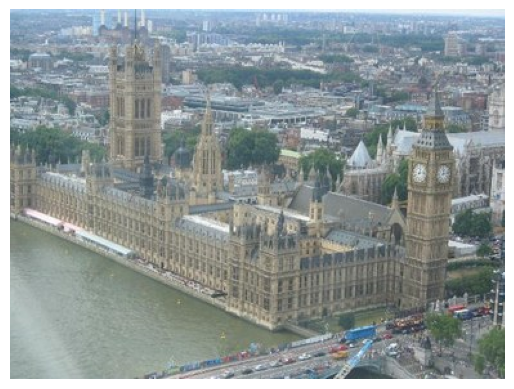

1.000  A wide panned shot of London at daytime.
0.000  a photo of a street
0.000  a photo of a pizza
0.000  a photo of a dog
0.000  a diagram of a neural network


In [10]:
from transformers import CLIPModel, CLIPProcessor

clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").eval()
clip_processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

photo = Image.open(CAPTION_IMAGES[0]).convert("RGB")
sentences = ["a photo of a dog", "a photo of a pizza", "a photo of a street",
             CAPTIONS.caption[0], "a diagram of a neural network"]
batch = clip_processor(text=sentences, images=photo, return_tensors="pt", padding=True)
probabilities = clip(**batch).logits_per_image.softmax(-1)[0]
plt.imshow(photo); plt.axis("off"); plt.show()
for p, s in sorted(zip(probabilities.tolist(), sentences), reverse=True):
    print(f"{p:.3f}  {s}")

## Section 2 — CLIP: search, measure, classify, break  *(~55 min)*

Five tasks on the 200 image–caption pairs:

1. **Embed** every image and every caption; check they share one space.
2. **Search** both ways: text → image and image → text.
3. **Measure** it: Recall@1, Recall@5, MRR.
4. **Zero-shot classification** on yesterday's five classes, against yesterday's probe.
5. **Break it** with the 8 hard captions.

<div dir="rtl" align="right">

## القسم ٢ — CLIP: ابحث، وقِس، وصنّف، واكسر  *(≈٥٥ دقيقة)*

خمس مهام على أزواج الصورة والتعليق الـ٢٠٠:

١. **ضمّن** كل صورة وكل تعليق؛ وتحقّق من أنها تتشارك فضاءً واحدًا.
٢. **ابحث** في الاتجاهين: من النص إلى الصورة ومن الصورة إلى النص.
٣. **قِس** ذلك: Recall@1 وRecall@5 وMRR.
٤. **صنّف بلا تدريب** فئات الأمس الخمس، مقابل فحص الأمس.
٥. **اكسره** بالتعليقات الصعبة الثمانية.

</div>

### Task 1 — Embed images and captions

`clip.get_image_features(pixel_values=...)` and `clip.get_text_features(input_ids=...,
attention_mask=...)` each return an output whose `.pooler_output` is one vector per input. Normalise
the rows so a dot product is a cosine. Then `SIMILARITY = image vectors @ caption vectors.T` is a
200×200 table: row *i* is image *i* against every caption.

<div dir="rtl" align="right">

### المهمّة ١ — ضمّن الصور والتعليقات

يُعيد كلٌّ من `clip.get_image_features(pixel_values=...)` و`clip.get_text_features(input_ids=...,
attention_mask=...)` خرجًا فيه `.pooler_output`: متّجه واحد لكل مُدخل. طبّع الصفوف ليصير الضرب النقطي جيبَ
تمام. وعندئذ `SIMILARITY = image vectors @ caption vectors.T` جدول ٢٠٠×٢٠٠: الصف *i* هو الصورة *i* مقابل
كل التعليقات.

</div>

In [14]:

# ────────────────────────────────────────────────────────────────────
# 1) In embed_images: pixels = clip_processor(images=images, return_tensors="pt")["pixel_values"].
# 2) Then clip.get_image_features(pixel_values=pixels).pooler_output.numpy().
# 3) In embed_texts: tokens = clip_processor(text=texts, return_tensors="pt", padding=True, truncation=True),
#    then clip.get_text_features(input_ids=..., attention_mask=...).pooler_output.numpy().
#
# ١) في `embed_images`: ‏`pixels = clip_processor(images=images, return_tensors="pt")["pixel_values"]`.
# ٢) ثم `clip.get_image_features(pixel_values=pixels).pooler_output.numpy()`.
# ٣) في `embed_texts`: ‏`tokens = clip_processor(text=texts, return_tensors="pt", padding=True, truncation=True)`،
#    ثم `clip.get_text_features(input_ids=..., attention_mask=...).pooler_output.numpy()`.
# ────────────────────────────────────────────────────────────────────

def embed_images(paths, batch=32):
    """One unit-length CLIP vector per image file."""
    chunks = []
    for start in range(0, len(paths), batch):
        images = [Image.open(p).convert("RGB") for p in paths[start:start + batch]]

        pixels = clip_processor(
            images=images,
            return_tensors="pt"
        )["pixel_values"]

        vectors = clip.get_image_features(
            pixel_values=pixels
        ).pooler_output.detach().cpu().numpy()

        chunks.append(vectors)

    return normalise(np.concatenate(chunks))


def embed_texts(texts):
    """One unit-length CLIP vector per string."""
    tokens = clip_processor(
    text=list(texts),
    return_tensors="pt",
    padding=True,
    truncation=True
)

    vectors = clip.get_text_features(
        input_ids=tokens["input_ids"],
        attention_mask=tokens["attention_mask"]
    ).pooler_output.detach().cpu().numpy()

    return normalise(vectors)


started = time.perf_counter()
IMAGE_VECTORS = embed_images(CAPTION_IMAGES)
TEXT_VECTORS = embed_texts(CAPTIONS.caption)
SIMILARITY = IMAGE_VECTORS @ TEXT_VECTORS.T                  # (200 images, 200 captions)
print(f"images {IMAGE_VECTORS.shape}, captions {TEXT_VECTORS.shape} in {time.perf_counter() - started:.0f} s")
print("same dimension:", IMAGE_VECTORS.shape[1] == TEXT_VECTORS.shape[1])
print("similarity table:", SIMILARITY.shape)


images (200, 512), captions (200, 512) in 26 s
same dimension: True
similarity table: (200, 200)


### Task 2 — Search both ways

The **column** for caption *j* scores every image against that caption: its top entries are a
text → image search. The **row** for image *i* scores every caption against that image: an
image → text search. Same matrix, read two ways.

<div dir="rtl" align="right">

### المهمّة ٢ — ابحث في الاتجاهين

**العمود** الخاص بالتعليق *j* يقيّم كل صورة مقابل ذلك التعليق: وأعلى قيمه بحثٌ من النص إلى الصورة. و**الصف**
الخاص بالصورة *i* يقيّم كل تعليق مقابل تلك الصورة: بحثٌ من الصورة إلى النص. المصفوفة نفسها، تُقرأ بطريقتين.

</div>

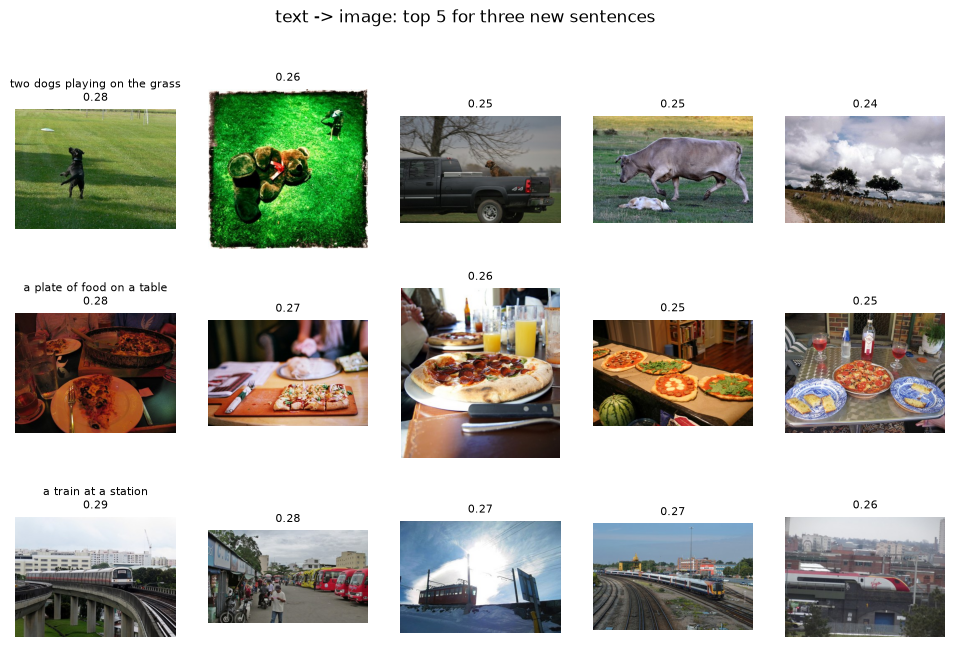

image -> text for image 7, a row of the same matrix:
  0.265  The sky is cloudy over a stop sign.   <- its own caption
  0.243  Four zebras are grazing in the open field
  0.240  A cow running in a field next to a dog.


In [15]:
# ────────────────────────────────────────────────────────────────────
# 1) np.argsort(-scores)[:k] gives the indices of the k largest scores, best first.
# 2) text -> image uses a column: SIMILARITY[:, query]. image -> text uses a row: SIMILARITY[i, :].
#
# ١) `np.argsort(-scores)[:k]` يُعطي فهارس أكبر k قيم، الأفضل أولًا.
# ٢) من النص إلى الصورة يستعمل عمودًا: `SIMILARITY[:, query]`. ومن الصورة إلى النص صفًّا: `SIMILARITY[i, :]`.
# ────────────────────────────────────────────────────────────────────

def top_k(scores, k=5):
    """Indices of the k highest scores, best first."""
    # TODO: Return the indices of the k largest values in `scores`, largest first.
    # مهمة: أعِد فهارس أكبر k قيم في `scores`، الأكبر أولًا.
    return np.argsort(-scores)[:k]
    
def retrieval_metrics(scores):
    ranks = own_rank(scores)

    return {
        "R@1": (ranks == 1).mean(),
        "R@5": (ranks <= 5).mean(),
        "MRR": (1 / ranks).mean()
    }

QUERIES = ["two dogs playing on the grass", "a plate of food on a table", "a train at a station"]
query_vectors = embed_texts(QUERIES)
fig, axes = plt.subplots(len(QUERIES), 5, figsize=(12, 7.5))
for row, (query, vector) in enumerate(zip(QUERIES, query_vectors)):
    scores = IMAGE_VECTORS @ vector                           # a free-text column
    for column, index in enumerate(top_k(scores)):
        axes[row, column].imshow(Image.open(CAPTION_IMAGES[index]).convert("RGB"))
        axes[row, column].set_title(f"{scores[index]:.2f}", fontsize=8); axes[row, column].axis("off")
    axes[row, 0].set_title(f"{query}\n{scores[top_k(scores)[0]]:.2f}", fontsize=8)
fig.suptitle("text -> image: top 5 for three new sentences"); plt.show()

print("image -> text for image 7, a row of the same matrix:")
for index in top_k(SIMILARITY[7], 3):
    print(f"  {SIMILARITY[7, index]:.3f}  {CAPTIONS.caption[index]}" + ("   <- its own caption" if index == 7 else ""))

### Task 3 — How good is the search?

For every image, find the **rank** of its own caption among all 200 (rank 1 = it came first). Then:

- **Recall@1** = fraction of images whose own caption ranked 1st;
- **Recall@5** = fraction whose own caption was in the top 5;
- **MRR** = mean of 1 / rank (1 if always first, 0.5 if always second, …).

Do it for both directions. Random guessing would give Recall@1 = 1/200 = 0.005.

<div dir="rtl" align="right">

### المهمّة ٣ — ما جودة البحث؟

لكل صورة، جِد **رتبة** تعليقها الخاص بين التعليقات الـ٢٠٠ كلها (الرتبة ١ = جاء أولًا). ثم:

- **Recall@1** = نسبة الصور التي جاء تعليقها الخاص في المرتبة الأولى؛
- **Recall@5** = نسبة الصور التي كان تعليقها الخاص ضمن الخمسة الأوائل؛
- **MRR** = متوسّط 1 / الرتبة (‏١ إن جاء أولًا دائمًا، و٠٫٥ إن جاء ثانيًا دائمًا، …).

افعل ذلك في الاتجاهين. والتخمين العشوائي يُعطي Recall@1 = 1/200 = 0.005.

</div>

In [17]:
# ────────────────────────────────────────────────────────────────────
# 1) ranks is a NumPy array of ranks (1 = best). (ranks == 1).mean() is Recall@1.
# 2) (ranks <= 5).mean() is Recall@5, and (1 / ranks).mean() is MRR.
#
# ١) `ranks` مصفوفة رتب (‏١ = الأفضل). و`(ranks == 1).mean()` هو Recall@1.
# ٢) `(ranks <= 5).mean()` هو Recall@5، و`(1 / ranks).mean()` هو MRR.
# ────────────────────────────────────────────────────────────────────

def own_rank(scores):
    """Row i's correct answer is column i: the rank (1 = best) of that answer in every row."""
    order = np.argsort(-scores, axis=1)
    return np.argmax(order == np.arange(len(scores))[:, None], axis=1) + 1


def retrieval_metrics(scores):
    ranks = own_rank(scores)
    # TODO: Return a dict with "R@1", "R@5" and "MRR" computed from `ranks`.
    # مهمة: أعِد قاموسًا فيه `"R@1"` و`"R@5"` و`"MRR"` محسوبةً من `ranks`.

    return {
        "R@1": (ranks == 1).mean(),
        "R@5": (ranks <= 5).mean(),
        "MRR": (1 / ranks).mean()
    }

METRICS = pd.DataFrame([{"direction": "image -> text", **retrieval_metrics(SIMILARITY)},
                        {"direction": "text -> image", **retrieval_metrics(SIMILARITY.T)}])
print(METRICS.round(3).to_string(index=False))

    direction   R@1   R@5   MRR
image -> text 0.570 0.850 0.701
text -> image 0.555 0.815 0.676


### Task 4 — Classify with zero labels

Turn each class name into a sentence, `"a photo of a {class}"`, embed the five sentences, and give
every image the class whose sentence is most similar. No training at all. Compare with yesterday's
DINOv2 probe, which needed 320 labels.

<div dir="rtl" align="right">

### المهمّة ٤ — صنّف بلا تسميات

حوّل كل اسم فئة إلى جملة `"a photo of a {class}"`، وضمّن الجمل الخمس، وأعطِ كل صورة الفئة التي جملتها الأشبه
بها. دون أي تدريب. وقارن بفحص DINOv2 أمس، الذي احتاج ٣٢٠ تسمية.

</div>

In [18]:
# ────────────────────────────────────────────────────────────────────
# 1) prompts = embed_texts([template.format(c=name) for name in CLASSES]) — five vectors.
# 2) scores = CLASS_VECTORS @ prompts.T is (400, 5); .argmax(1) picks a class per image.
# 3) Accuracy = (np.array(CLASSES)[best] == CLASS_LABELS).mean().
#
# ١) `prompts = embed_texts([template.format(c=name) for name in CLASSES])` — خمسة متّجهات.
# ٢) `scores = CLASS_VECTORS @ prompts.T` شكلها `(400, 5)`؛ و`.argmax(1)` يختار فئة لكل صورة.
# ٣) الدقّة = `(np.array(CLASSES)[best] == CLASS_LABELS).mean()`.
# ────────────────────────────────────────────────────────────────────

CLASS_VECTORS = embed_images(CLASS_PATHS)


def zero_shot(template):
    """Accuracy on the 400 class images, using only the five class names."""
    # TODO: Embed one sentence per class, pick the best-matching class per image, and return the accuracy.
    # مهمة: ضمّن جملة واحدة لكل فئة، واختر الفئة الأنسب لكل صورة، وأعِد الدقّة.
    prompts = embed_texts([
        template.format(c=name) for name in CLASSES
    ])

    scores = CLASS_VECTORS @ prompts.T
    best = scores.argmax(axis=1)

    return (np.array(CLASSES)[best] == CLASS_LABELS).mean()

ZERO_SHOT = zero_shot("a photo of a {c}")
print(pd.DataFrame([("CLIP zero-shot", 0, ZERO_SHOT),
                    ("DINOv2 + linear probe (D1)", 320, PROBE["dino_probe"]),
                    ("ResNet-18 fine-tune (W4D5)", 320, PROBE["w4d5_finetune"])],
                   columns=["method", "labels", "accuracy"]).to_string(index=False))
print("\nother wordings:", {t: round(zero_shot(t), 4) for t in ["{c}", "a blurry photo of a {c}", "صورة {c}"]})

                    method  labels  accuracy
            CLIP zero-shot       0    0.9975
DINOv2 + linear probe (D1)     320    0.9875
ResNet-18 fine-tune (W4D5)     320    0.9250

other wordings: {'{c}': np.float64(0.995), 'a blurry photo of a {c}': np.float64(0.9925), 'صورة {c}': np.float64(0.995)}


### Task 5 — Break it

The last 8 captions were written to be **true** of their own image. For each one, find the rank of
its own image among all 200 (the caption's column). Rank 1 means CLIP found it. Look at which kinds
fail: CLIP learned which *words* go with which *pictures*, not how to count or tell left from right —
and it saw far less Arabic than English.

<div dir="rtl" align="right">

### المهمّة ٥ — اكسره

كُتبت التعليقات الثمانية الأخيرة لتكون **صادقة** عن صورتها. لكلٍّ منها، جِد رتبة صورتها الخاصة بين الصور
الـ٢٠٠ كلها (عمود التعليق). الرتبة ١ تعني أن CLIP وجدها. انظر أيّ الأنواع يفشل: تعلّم CLIP أيّ *الكلمات* تأتي
مع أيّ *الصور*، لا كيف يعدّ أو يميّز اليمين من اليسار — ورأى من العربية أقلّ بكثير مما رأى من الإنجليزية.

</div>

In [19]:
# ────────────────────────────────────────────────────────────────────
# 1) TEXT_RANKS = own_rank(SIMILARITY.T): for caption j, the rank of image j in its column.
# 2) HARD["rank_of_own_image"] = TEXT_RANKS[HARD.index].
#
# ١) `TEXT_RANKS = own_rank(SIMILARITY.T)`: لكل تعليق j، رتبة الصورة j في عموده.
# ٢) `HARD["rank_of_own_image"] = TEXT_RANKS[HARD.index]`.
# ────────────────────────────────────────────────────────────────────

HARD = CAPTIONS[CAPTIONS.hard_case.notna()].copy()
# TODO: Rank every caption's own image (text -> image) and store the hard cases' ranks in a new column.
# مهمة: رتّب صورة كل تعليق الخاصة (من النص إلى الصورة) وخزّن رتب الحالات الصعبة في عمود جديد.
TEXT_RANKS = own_rank(SIMILARITY.T)
HARD["rank_of_own_image"] = TEXT_RANKS[HARD.index]
print(HARD[["hard_case", "caption", "rank_of_own_image"]].to_string(index=False))
ARABIC_RANK = int(HARD.loc[HARD.hard_case == "arabic", "rank_of_own_image"].iloc[0])
TWIN_RANK = int(HARD.loc[HARD.hard_case == "arabic_twin", "rank_of_own_image"].iloc[0])
print(f"\nthe Arabic caption's image ranks {ARABIC_RANK}; its English twin's ranks {TWIN_RANK}")

    hard_case                                     caption  rank_of_own_image
     counting               three cars parked on a street                176
     counting            two zebras standing side by side                  2
     counting               four people standing together                117
      spatial               a dog to the left of a person                  5
      spatial               a bus to the left of a person                 12
text_in_image a sign with the word STOP written across it                  8
       arabic                   صورة لقطة جالسة على أريكة                173
  arabic_twin          a photo of a cat sitting on a sofa                  6

the Arabic caption's image ranks 173; its English twin's ranks 6


### Takeaway

CLIP is a superb **search engine** and a strong zero-shot classifier on everyday classes. It is weak
exactly where a sentence needs structure — numbers, positions, written words — and on languages that
were rare in its training data.

<div dir="rtl" align="right">

### الخلاصة

CLIP **محرّك بحث** ممتاز ومصنِّف قويّ بلا تدريب على الفئات اليومية. وهو ضعيف تحديدًا حيث تحتاج الجملة إلى
بنية — الأعداد، والمواضع، والكلمات المكتوبة — وفي اللغات التي كانت نادرة في بيانات تدريبه.

</div>

## Section 3 — A VLM: ask the image  *(~35 min)*

CLIP can only *score* a sentence you already wrote. A VLM *writes* the answer. It has three parts:

1. a **vision encoder** — a ViT, like yesterday's — that turns the image into patch vectors;
2. a **connector** that turns those vectors into a few **image tokens** in the language model's space;
3. a **language model** that reads the image tokens followed by your question, and generates text.

Three tasks: open the model, ask it things, and test it on the questions CLIP failed.

<div dir="rtl" align="right">

## القسم ٣ — نموذج رؤية ولغة: اسأل الصورة  *(≈٣٥ دقيقة)*

لا يستطيع CLIP إلا أن *يقيّم* جملة كتبتها أنت. أما نموذج الرؤية واللغة فـ*يكتب* الجواب. وله ثلاثة أجزاء:

١. **مُرمِّز رؤية** — ViT مثل ViT الأمس — يحوّل الصورة إلى متّجهات رقع؛
٢. **موصِّل** يحوّل تلك المتّجهات إلى عدد قليل من **رموز الصورة** في فضاء النموذج اللغوي؛
٣. **نموذج لغوي** يقرأ رموز الصورة يليها سؤالك، ويولّد نصًّا.

ثلاث مهام: افتح النموذج، واسأله، واختبره على الأسئلة التي فشل فيها CLIP.

</div>

### Task 1 — Open the VLM

Load SmolVLM and count the parameters of its three parts (`vlm.model.vision_model`,
`vlm.model.connector`, `vlm.model.text_model`). Then prepare one image with a question and count the
image tokens in `input_ids`: every position equal to `vlm.config.image_token_id` is one image token.

The processor can feed the image whole, as one 512×512 tile, or split it into a grid of tiles plus a
small overview. Count the tokens both ways.

<div dir="rtl" align="right">

### المهمّة ١ — افتح نموذج الرؤية واللغة

حمّل SmolVLM وعُدّ معاملات أجزائه الثلاثة (`vlm.model.vision_model` و`vlm.model.connector`
و`vlm.model.text_model`). ثم جهّز صورة واحدة مع سؤال وعُدّ رموز الصورة في `input_ids`: كل موضع يساوي
`vlm.config.image_token_id` رمزُ صورة واحد.

يستطيع المعالج أن يُدخل الصورة كاملة، بلاطةً واحدة ٥١٢×٥١٢، أو أن يقسمها إلى شبكة بلاطات مع نظرة عامة صغيرة.
عُدّ الرموز بالطريقتين.

</div>

In [20]:
from transformers import AutoModelForImageTextToText, AutoProcessor

VLM_NAME = "HuggingFaceTB/SmolVLM-500M-Instruct"
vlm = AutoModelForImageTextToText.from_pretrained(VLM_NAME, dtype=torch.float32).eval()
LOW = AutoProcessor.from_pretrained(VLM_NAME, do_image_splitting=False)    # the image as one tile
HIGH = AutoProcessor.from_pretrained(VLM_NAME, do_image_splitting=True)    # split into tiles


def prepare(image, question, processor):
    """The chat-formatted inputs for one image and one question."""
    messages = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": question}]}]
    prompt = processor.apply_chat_template(messages, add_generation_prompt=True)
    return processor(text=prompt, images=[image], return_tensors="pt")

config.json:   0%|          | 0.00/7.34k [00:00<?, ?B/s]

[transformers] Model config: pad_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 128002. This may result in unexpected behavior.


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.02GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/489 [00:00<?, ?it/s]

...

vocab.json:   0%|          | 0.00/801k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/466k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/4.74k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/1.07k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.55M [00:00<?, ?B/s]

In [21]:
# ────────────────────────────────────────────────────────────────────
# 1) sum(p.numel() for p in part.parameters()) counts a part's parameters.
# 2) (inputs["input_ids"] == vlm.config.image_token_id).sum() counts the image tokens.
#
# ١) `sum(p.numel() for p in part.parameters())` يعدّ معاملات جزء.
# ٢) `(inputs["input_ids"] == vlm.config.image_token_id).sum()` يعدّ رموز الصورة.
# ────────────────────────────────────────────────────────────────────

PARTS = {"vision encoder": vlm.model.vision_model, "connector": vlm.model.connector,
         "language model": vlm.model.text_model}
image = Image.open(CAPTION_IMAGES[0]).convert("RGB")
# TODO: Count each part's parameters into PART_PARAMS, and the image tokens with LOW and HIGH into IMAGE_TOKENS.
# مهمة: عُدّ معاملات كل جزء في `PART_PARAMS`، ورموز الصورة مع `LOW` و`HIGH` في `IMAGE_TOKENS`.
PART_PARAMS = {
    name: sum(p.numel() for p in part.parameters())
    for name, part in PARTS.items()
}

IMAGE_TOKENS = {
    "LOW": int(
        (prepare(image, "Describe this image.", LOW)["input_ids"]
         == vlm.config.image_token_id).sum().item()
    ),
    "HIGH": int(
        (prepare(image, "Describe this image.", HIGH)["input_ids"]
         == vlm.config.image_token_id).sum().item()
    )
}
for name, n in PART_PARAMS.items():
    print(f"{name:<15} {n / 1e6:6.1f} M parameters")
print("image tokens:", IMAGE_TOKENS)
print("a 512x512 tile is 32 x 32 = 1024 patches; the connector squeezes them into 64 tokens.")

vision encoder    86.4 M parameters
connector         11.8 M parameters
language model   361.9 M parameters
image tokens: {'LOW': 64, 'HIGH': 832}
a 512x512 tile is 32 x 32 = 1024 patches; the connector squeezes them into 64 tokens.


### Task 2 — Ask it something

Write `ask(image, question, processor)`: prepare the inputs, call `vlm.generate(...)` greedily, and
decode **only the new tokens** (the output starts with the whole prompt again). Then caption three
photos and time one answer.

<div dir="rtl" align="right">

### المهمّة ٢ — اسأله شيئًا

اكتب `ask(image, question, processor)`: جهّز المدخلات، ونادِ `vlm.generate(...)` بالتوليد الجشِع، وفكّ ترميز
**الرموز الجديدة فقط** (يبدأ الخرج بالمُحثّ كله من جديد). ثم اكتب تعليقًا لثلاث صور وقِس زمن جواب واحد.

</div>

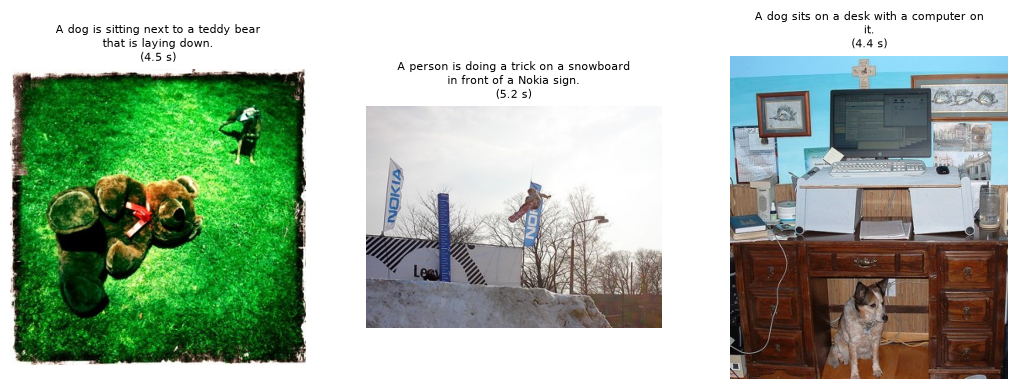

In [22]:
# ────────────────────────────────────────────────────────────────────
# 1) inputs = prepare(image, question, processor); out = vlm.generate(**inputs, max_new_tokens=..., do_sample=False).
# 2) The new tokens are out[:, inputs["input_ids"].shape[1]:].
# 3) processor.batch_decode(new_tokens, skip_special_tokens=True)[0].strip() is the answer.
#
# ١) `inputs = prepare(image, question, processor)`؛ ثم `out = vlm.generate(**inputs, max_new_tokens=..., do_sample=False)`.
# ٢) الرموز الجديدة هي `out[:, inputs["input_ids"].shape[1]:]`.
# ٣) `processor.batch_decode(new_tokens, skip_special_tokens=True)[0].strip()` هو الجواب.
# ────────────────────────────────────────────────────────────────────

def ask(image, question, processor=LOW, max_new_tokens=30):
    """The VLM's answer to one question about one image."""
    # TODO: Generate greedily, keep only the tokens after the prompt, and return them decoded as text.
    # مهمة: ولّد بالطريقة الجشِعة، واحتفظ بالرموز التي بعد المُحثّ فقط، وأعِدها نصًّا مفكوك الترميز.
    inputs = prepare(image, question, processor)

    out = vlm.generate(
        **inputs,
        max_new_tokens=max_new_tokens,
        do_sample=False
    )

    new_tokens = out[:, inputs["input_ids"].shape[1]:]

    return processor.batch_decode(
        new_tokens,
        skip_special_tokens=True
    )[0].strip()

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, index in zip(axes, [3, 50, 120]):
    picture = Image.open(CAPTION_IMAGES[index]).convert("RGB")
    started = time.perf_counter()
    answer = ask(picture, "Describe this image in one short sentence.")
    ax.imshow(picture); ax.axis("off")
    ax.set_title(textwrap.fill(answer, 40) + f"\n({time.perf_counter() - started:.1f} s)", fontsize=8)
plt.show()

### Task 3 — The questions CLIP failed

Ask the VLM about the six counting, left/right and text images, once with `LOW` (64 image tokens) and
once with `HIGH` (832). The `CORRECT` rules below mark each answer right or wrong. Fill the table with
how many it got right and how long it took per answer.

<div dir="rtl" align="right">

### المهمّة ٣ — الأسئلة التي فشل فيها CLIP

اسأل نموذج الرؤية واللغة عن صور العدّ واليمين واليسار والنص الستّ، مرّةً بـ`LOW` (‏٦٤ رمز صورة) ومرّةً بـ`HIGH`
(‏٨٣٢). وتحكم قواعد `CORRECT` أدناه على كل جواب بالصواب أو الخطأ. املأ الجدول بعدد الإجابات الصحيحة وبالزمن
لكل جواب.

</div>

In [23]:
# ────────────────────────────────────────────────────────────────────
# 1) Loop over QUESTIONS; for each, open its image from CAPTION_ROOT / "images" / file.
# 2) For each processor in (LOW, HIGH): time ask(...), test CORRECT[file](answer.lower()), and append a row.
#
# ١) دُر على `QUESTIONS`؛ وافتح صورة كلٍّ منها من `CAPTION_ROOT / "images" / file`.
# ٢) لكل معالج في `(LOW, HIGH)`: قِس زمن `ask(...)`، واختبر `CORRECT[file](answer.lower())`، وأضِف صفًّا.
# ────────────────────────────────────────────────────────────────────

QUESTIONS = {
    "000000004551.jpg": "How many cars are in the picture? Answer with one number.",
    "000000020701.jpg": "How many zebras are in the picture? Answer with one number.",
    "000000000723.jpg": "How many people are in the picture? Answer with one number.",
    "000000005946.jpg": "Is the dog on the left or on the right of the person?",
    "000000009999.jpg": "Is the bus on the left or on the right of the person?",
    "000000009176.jpg": "What word is written on the sign?",
}
CORRECT = {                                  # the truth, from the captions in the dataset
    "000000004551.jpg": lambda a: "3" in a or "three" in a,
    "000000020701.jpg": lambda a: "2" in a or "two" in a,
    "000000000723.jpg": lambda a: "4" in a or "four" in a,
    "000000005946.jpg": lambda a: "left" in a and "right" not in a,
    "000000009999.jpg": lambda a: "left" in a and "right" not in a,
    "000000009176.jpg": lambda a: "stop" in a,
}
rows = []
# TODO: Ask every question with LOW and with HIGH; append (file, resolution, answer, correct, seconds) to rows.
# مهمة: اسأل كل سؤال بـ`LOW` وبـ`HIGH`؛ وأضِف `(file, resolution, answer, correct, seconds)` إلى `rows`.
for file, question in QUESTIONS.items():
    picture = Image.open(CAPTION_ROOT / "images" / file).convert("RGB")

    for resolution, processor in [("LOW", LOW), ("HIGH", HIGH)]:
        started = time.perf_counter()

        answer = ask(picture, question, processor=processor)

        seconds = time.perf_counter() - started
        correct = CORRECT[file](answer.lower())

        rows.append((file, resolution, answer, correct, seconds))
VLM_TABLE = pd.DataFrame(rows, columns=["file", "resolution", "answer", "correct", "seconds"])
print(VLM_TABLE.assign(answer=VLM_TABLE.answer.str[:50]).to_string(index=False))
SUMMARY = VLM_TABLE.groupby("resolution").agg(right=("correct", "sum"), seconds=("seconds", "mean"))
print("\n", SUMMARY.round(1))

            file resolution                                      answer  correct   seconds
000000004551.jpg        LOW                                          2.    False  3.756526
000000004551.jpg       HIGH                                          5.    False 31.385797
000000020701.jpg        LOW                                          2.     True  3.719579
000000020701.jpg       HIGH                                          2.     True 30.058916
000000000723.jpg        LOW                                          3.    False  3.077789
000000000723.jpg       HIGH                                          4.     True 36.106312
000000005946.jpg        LOW       The dog is on the left of the person.     True  4.442055
000000005946.jpg       HIGH  The dog is on the left side of the person.     True 31.285094
000000009999.jpg        LOW      The bus is on the right of the person.    False  3.129693
000000009999.jpg       HIGH The bus is on the right side of the person.    False 33.218657

### Write-up

In **one sentence each**: when would you use CLIP, and when a VLM? Think about cost per image, about
searching a million photos versus answering one question, and about what each one got wrong today.

> *Example: "CLIP to search or sort many images — one cheap vector each, compared in microseconds;
> a VLM when someone needs an answer about one image, paying seconds per question, and more image
> tokens when the answer is in the small details."*

<div dir="rtl" align="right">

### كتابة

في **جملة واحدة لكلٍّ منهما**: متى تستعمل CLIP، ومتى نموذج رؤية ولغة؟ فكّر في الكلفة لكل صورة، وفي البحث في
مليون صورة مقابل الإجابة عن سؤال واحد، وفيما أخطأ فيه كلٌّ منهما اليوم.

> *مثال: «CLIP للبحث في صور كثيرة أو فرزها — متّجه رخيص لكلٍّ منها يُقارَن في أجزاء من الألف من الثانية؛
> ونموذج الرؤية واللغة حين يحتاج أحدٌ جوابًا عن صورة واحدة، بكلفة ثوانٍ لكل سؤال، ومع رموز صورة أكثر حين يكون
> الجواب في التفاصيل الصغيرة.»*

</div>

In [ ]:
YOUR_ANSWER = """
(write your two sentences here)
"""

## Wrap-up

- CLIP = two encoders trained so that matching images and captions land close together. Search,
  retrieval metrics and zero-shot classification are all read off one similarity matrix.
- It fails on counting, positions, text in images, and under-represented languages.
- A VLM = vision encoder → connector → language model. An image is just more tokens in the prompt —
  and more image tokens see more detail, at a price you measured.

Tomorrow (**D3**) the input changes again: sound. A waveform becomes a spectrogram, the spectrogram
becomes tokens, and a transformer writes down what was said.

<div dir="rtl" align="right">

## الخلاصة

- CLIP = مُرمِّزان دُرّبا بحيث تقع الصور والتعليقات المتطابقة قريبة بعضها من بعض. والبحث ومقاييس الاسترجاع
  والتصنيف بلا تدريب كلها تُقرأ من مصفوفة تشابه واحدة.
- ويفشل في العدّ، والمواضع، والنص داخل الصور، واللغات القليلة التمثيل.
- نموذج الرؤية واللغة = مُرمِّز رؤية ← موصِّل ← نموذج لغوي. والصورة مجرّد رموز إضافية في المُحثّ — ورموز صورة
  أكثر ترى تفاصيل أكثر، بثمن قِسته.

وغدًا (**اليوم ٣**) يتغيّر المُدخل مرّة أخرى: الصوت. تصير الموجة مخطّطًا طيفيًا، ويصير المخطّط رموزًا، ويكتب
محوّلٌ ما قيل.

</div>

In [ ]:
check(IMAGE_VECTORS.shape == (200, 512) and TEXT_VECTORS.shape == (200, 512)
      and np.allclose(np.linalg.norm(IMAGE_VECTORS, axis=1), 1, atol=1e-5),
      f"images and captions must be 512-number unit vectors in one space — got {IMAGE_VECTORS.shape}, {TEXT_VECTORS.shape}",
      f"يجب أن تكون الصور والتعليقات متّجهات وحدة من ٥١٢ عددًا في فضاء واحد — والناتج {IMAGE_VECTORS.shape}، {TEXT_VECTORS.shape}")
check(list(top_k(np.array([0.1, 0.9, 0.5]), 2)) == [1, 2],
      "top_k must return the indices of the largest scores, best first",
      "يجب أن تُعيد `top_k` فهارس أكبر القيم، الأفضل أولًا")
check(all(METRICS["R@5"] >= METRICS["R@1"]) and METRICS["R@1"].min() > 0.3,
      f"Recall@5 must be at least Recall@1, and both directions far above chance (0.005) — got\n{METRICS}",
      f"يجب أن يكون Recall@5 لا أقلّ من Recall@1، والاتجاهان فوق الصدفة (‏٠٫٠٠٥) بكثير — والناتج\n{METRICS}")
check(ZERO_SHOT > 0.9,
      f"zero-shot CLIP must classify the five everyday classes above 0.9 with no labels — got {ZERO_SHOT:.4f}",
      f"يجب أن يصنّف CLIP بلا تدريب الفئات اليومية الخمس فوق ٠٫٩ دون تسميات — والناتج {ZERO_SHOT:.4f}")
check(ARABIC_RANK > TWIN_RANK,
      f"the Arabic caption must rank its image worse than the English twin does — got {ARABIC_RANK} vs {TWIN_RANK}",
      f"يجب أن يرتّب التعليق العربي صورته أسوأ مما يفعل توأمه الإنجليزي — والناتج {ARABIC_RANK} مقابل {TWIN_RANK}")
check(IMAGE_TOKENS["LOW"] < IMAGE_TOKENS["HIGH"] and len(VLM_TABLE) == 12,
      f"HIGH must spend more image tokens than LOW, and all 6 questions must be asked both ways — got {IMAGE_TOKENS}, {len(VLM_TABLE)} rows",
      f"يجب أن يُنفق `HIGH` رموز صورة أكثر من `LOW`، وأن تُسأل الأسئلة الستّة بالطريقتين — والناتج {IMAGE_TOKENS}، {len(VLM_TABLE)} صفًّا")
report()